# E.3 Connect clinical data to fitness carefully

HbAS is less common among people with severe malaria. Does that observation give us the genotype fitnesses in a balancing-selection model?

The case–control data identify protection against one clinical outcome. Relative fitness is expected genetic contribution across survival and reproduction. The two quantities are connected by biology, but they are not interchangeable.


## Observed data and expected result

At the Mali site in the MalariaGEN study, HbAS occurred in 4 of 453 severe-malaria cases and 28 of 344 controls. For a raw comparison of HbAS with non-HbAS,

$$
\widehat{OR}=\frac{4/449}{28/316}.
$$

We expect a value well below one. That result supports clinical protection. It does not identify $w_{AA}$, $w_{AS}$, and $w_{SS}$.


In [1]:
library(hpgR)

count <- matrix(
  c(4, 449, 28, 316),
  nrow = 2, byrow = TRUE,
  dimnames = list(group = c('Severe malaria', 'Control'),
                  genotype = c('HbAS', 'Non-HbAS'))
)

odds_ratio <- (count[1, 'HbAS'] / count[1, 'Non-HbAS']) /
  (count[2, 'HbAS'] / count[2, 'Non-HbAS'])
hb_as_fraction <- count[, 'HbAS'] / rowSums(count)

stopifnot(sum(count[1, ]) == 453, sum(count[2, ]) == 344)
c(raw_odds_ratio = odds_ratio, hb_as_cases = hb_as_fraction[1],
  hb_as_controls = hb_as_fraction[2])

raw_odds_ratio hb_as_cases.Severe malaria     hb_as_controls.Control 
               0.100540885                0.008830022                0.081395349

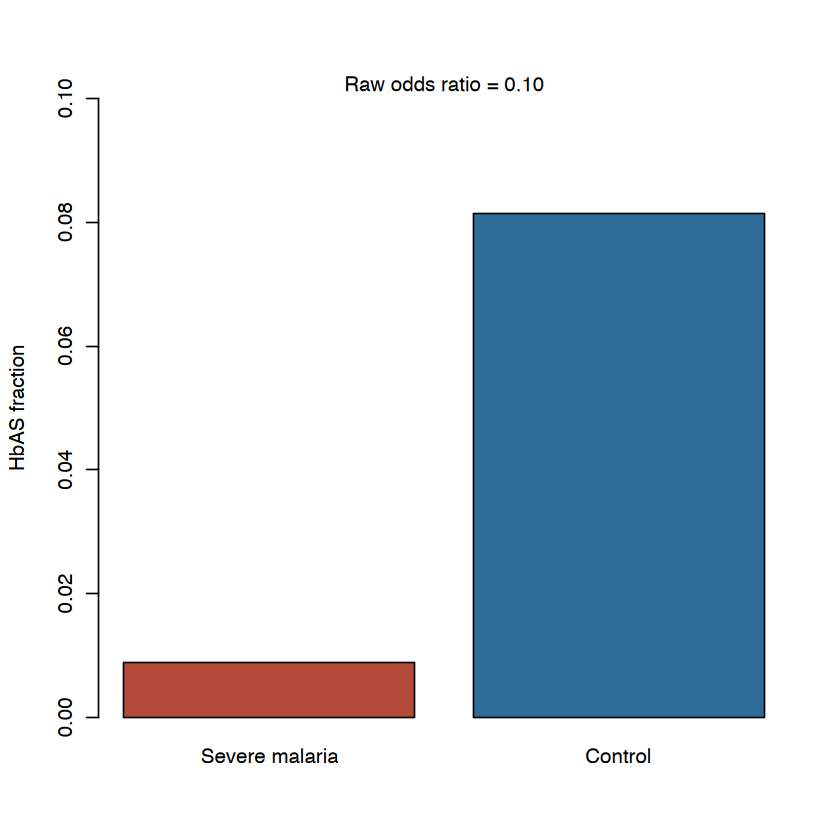

In [2]:
barplot(hb_as_fraction, col = c('#B44A3A', '#306C9A'), ylim = c(0, 0.10),
        ylab = 'HbAS fraction', names.arg = names(hb_as_fraction))
mtext(sprintf('Raw odds ratio = %.2f', odds_ratio), side = 3, line = 0.2)

## Why the odds ratio does not determine an equilibrium

For the idealized heterozygote-advantage model $w_{AA}=1-s_A$, $w_{AS}=1$, and $w_{SS}=1-s_S$, the HbS equilibrium is $p_S^*=s_A/(s_A+s_S)$. The case–control table does not provide either selection coefficient. Two teaching fitness tables can therefore agree that HbAS has the highest fitness and still imply different equilibria.


In [3]:
fitness_model <- data.frame(
  model = c('Model 1', 'Model 2'),
  w_AA = c(0.90, 0.60),
  w_AS = c(1.00, 1.00),
  w_SS = c(0.20, 0.20)
)
fitness_model$p_S_equilibrium <- apply(
  fitness_model[, c("w_SS", "w_AS", "w_AA")], 1, balancedFrequency
)
fitness_model

model,w_AA,w_AS,w_SS,p_S_equilibrium
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
Model 1,0.9,1,0.2,0.1111111
Model 2,0.6,1,0.2,0.3333333


The two equilibrium values differ because the unmeasured costs differ. They are not estimates from Mali; they demonstrate the missing information.

## What to remember

The raw odds ratio is about 0.10 and supports strong protection against severe malaria in this sample. Balancing selection needs a complete genotype-fitness model. A clinical odds ratio cannot be inserted into that model as a fitness value.

**Sources.** Malaria Genomic Epidemiology Network (2014), *Nature Genetics* 46:1197–1204, Supplementary Table 11; Pritchard, *An Owner's Guide to the Human Genome*, Section 2.6. The odds ratio is an unadjusted calculation from one site; the fitness tables are teaching values, not population estimates.
